# Business Aucumen
 
## Business goals

1. The revenue of the insurance company depends on number of policies sold and cost of the policies. 
1. The expenditure of insurance company is number of claims done by the client or the customer. 
1. More the claims or bigger the claims decreases the profits of the insurance company. 
3. We will use machine learning model to predict the claims and the amount he will claim from the given data set. 
4. This will help us to charge the customer premium who is most likely to claim this will helps us for better pricing decisions.
1. Machine learning model may also give us the factors that has most responsible for claims.

## Business Metrics 

### 1. Success  metrics

1. Number of high claiming induvidual identified
2. Approximate costing cutting done
3. Identifing key factors for the claim that will help risk team better

### Evolution metrics

1. Checking key scores like accuracy score, presission score and clasification matrix.
1. Better to have presision score as good as possible.
2. For clasification matrix train model such that false negative remain minimum and optimum for the false positive.

## Importing necessary libraries

In [1]:
# Importing necessary library required for 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load and inspect the dataset

In [2]:
# Loading the dataset
insurance_df = pd.read_csv(r"G:\data_analytics_and_genAI\Capstone_project\dataset.csv")
display("Shape of the dataset:", insurance_df.shape)  # Displaying the shape of the dataset
display("First few rows of the dataset:")  # Displaying a message
pd.set_option("display.max_columns", 10000)  # Setting to display all columns in the dataset
display(insurance_df.head())  # Displaying the first few rows of the dataset

'Shape of the dataset:'

(58592, 44)

'First few rows of the dataset:'

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


# Exploring data set 

### Checking first few rows of dataset

### Checking data types of columns

In [3]:
# Thinking data type of all columns
display("Data types of all columns:")  # Displaying a message
display(insurance_df.dtypes)  # Displaying the data types of all columns

'Data types of all columns:'

policy_id                            object
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                         object
population_density                    int64
make                                  int64
segment                              object
model                                object
fuel_type                            object
max_torque                           object
max_power                            object
engine_type                          object
airbags                               int64
is_esc                               object
is_adjustable_steering               object
is_tpms                              object
is_parking_sensors                   object
is_parking_camera                    object
rear_brakes_type                     object
displacement                          int64
cylinder                              int64
transmission_type               

### Checking for missing value in each columns

In [4]:
# finding missing value
display("Missing values in each column:")  # Displaying a message
for col in insurance_df.columns:
    missing_count = insurance_df[col].isnull().sum()  # Counting missing values in each column
    if missing_count > 0:
        display(f"Column '{col}' has {missing_count} missing values.")  # Displaying the count of missing values for columns with missing data
        insurance_df[col].fillna(insurance_df[col].mode()[0], inplace=True)  # Filling missing values with the mode of the column
    else:
        display(f"Column '{col}' has no missing values.")  # Displaying a message for columns with no missing data


'Missing values in each column:'

"Column 'policy_id' has no missing values."

"Column 'policy_tenure' has no missing values."

"Column 'age_of_car' has no missing values."

"Column 'age_of_policyholder' has no missing values."

"Column 'area_cluster' has no missing values."

... (35 outputs left out)

"Column 'is_ecw' has no missing values."

"Column 'is_speed_alert' has no missing values."

"Column 'ncap_rating' has no missing values."

"Column 'is_claim' has no missing values."

No missing value

### Checking for duplicate rows in dataset

In [5]:
# Check the number of duplicate rows
if insurance_df.duplicated().sum() > 0:
    insurance_df.drop_duplicates(inplace=True)  # Dropping duplicate rows if any
else:
    print(f'Total number of duplicate rows are 0')  # Displaying a message if there are no duplicate rows

Total number of duplicate rows are 0


Looking for duplicate policy ID using if else

In [6]:
if insurance_df['policy_id'].nunique() == insurance_df.shape[0]:
    print("All policy IDs are unique.")
else:
    print("There are duplicate policy IDs.")

All policy IDs are unique.


### Checking for number of unique values in coluns

In [7]:
# Creating list of column 
column = insurance_df.columns
# Number of unique values in all column
for col in column:
    
    print(f'The unique values in {col} are {insurance_df[col].nunique()}')

The unique values in policy_id are 58592
The unique values in policy_tenure are 58592
The unique values in age_of_car are 49
The unique values in age_of_policyholder are 75
The unique values in area_cluster are 22
The unique values in population_density are 22
The unique values in make are 5
The unique values in segment are 6
The unique values in model are 11
The unique values in fuel_type are 3
The unique values in max_torque are 9
The unique values in max_power are 9
The unique values in engine_type are 11
The unique values in airbags are 3
The unique values in is_esc are 2
The unique values in is_adjustable_steering are 2
The unique values in is_tpms are 2
The unique values in is_parking_sensors are 2
The unique values in is_parking_camera are 2
The unique values in rear_brakes_type are 2
The unique values in displacement are 9
The unique values in cylinder are 2
The unique values in transmission_type are 2
The unique values in gear_box are 2
The unique values in steering_type are 3

## Checking the is_claim columns with imbalance ratio

In [8]:
val_counts = pd.DataFrame(insurance_df['is_claim'].value_counts())
display("Value counts for 'is_claim' column:")  # Displaying a message
display(val_counts)  # Displaying the value counts for the 'is_claim' column
print(f'The imbalance ratio of the target variable is: { (val_counts.iloc[0, 0] / val_counts.iloc[1, 0]).round(0).__int__() }:1')  # Displaying the imbalance ratio of the target variable

"Value counts for 'is_claim' column:"

,count
is_claim,
0,54844
1,3748


The imbalance ratio of the target variable is: 15:1


There are no duplicate rows

## Standarding categorical boolean columns into boolean columns

In [9]:
# Detect boolean-like columns and convert them to bool dtype

# Collect boolean columns
boolean_columns = []
numeric_columns = []
categorical_columns = []
bool_values = {0, 1, 'False', 'No', 'True', 'Yes', 'no', 'yes'}
# bool_values is defined elsewhere in the notebook and contains accepted boolean representations
def column_grouping_function(insurance_df):
    column = insurance_df.columns
    boolean_columns = []
    bool_values = {0, 1, 'False', 'No', 'True', 'Yes', 'no', 'yes'}
    for col in column:
    # get unique non-null values for the column
        unique_vals = set(insurance_df[col].dropna().unique())
    # if all unique values are within the known boolean representations, mark the column as boolean
        if unique_vals and unique_vals.issubset(bool_values):
            boolean_columns.append(col)

            # show detected boolean columns
    print(boolean_columns)

# convert detected columns to boolean dtype
    for col in boolean_columns:
        if insurance_df[col].dtype != 'bool':
            insurance_df[col] = insurance_df[col].map({'Yes': True, 'No': False, 'True': True, 'False': False, 1: True, 0: False})



    # Display both lists
    return numeric_columns, categorical_columns

column_grouping_function(insurance_df)

['is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'is_claim']


([], [])

In [10]:
# making sure that the data types are changed to boolean
insurance_df.dtypes 

policy_id                            object
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                         object
population_density                    int64
make                                  int64
segment                              object
model                                object
fuel_type                            object
max_torque                           object
max_power                            object
engine_type                          object
airbags                               int64
is_esc                                 bool
is_adjustable_steering                 bool
is_tpms                                bool
is_parking_sensors                     bool
is_parking_camera                      bool
rear_brakes_type                     object
displacement                          int64
cylinder                              int64
transmission_type               

In [11]:
# Select numeric columns from the dataframe using numpy dtype
numeric_columns = insurance_df.select_dtypes(include=np.number).columns.tolist()

# Select categorical columns (object or category dtypes)
categorical_columns = insurance_df.select_dtypes(include=['object', 'category']).columns.tolist()

In [12]:
len(numeric_columns), len(categorical_columns)  # Displaying the number of numeric and categorical columns

(15, 11)

In [13]:
# Extract all numbers before 'bhp' in the max_power column
insurance_df['max_power'] = insurance_df['max_power'].str.extract(r'(\d+\.?\d*)').astype(float)
insurance_df['max_torque'] = insurance_df['max_torque'].str.extract(r'(\d+\.?\d*)').astype(float)


# Display the extracted values
insurance_df[['max_power', 'max_torque']].head(10)

,max_power,max_torque
0,40.36,60.0
1,40.36,60.0
2,40.36,60.0
3,88.50,113.0
4,67.06,91.0
5,113.45,250.0
6,88.77,200.0
7,88.50,113.0
8,113.45,250.0
9,88.50,113.0


In [14]:
insurance_df.dtypes

policy_id                            object
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                         object
population_density                    int64
make                                  int64
segment                              object
model                                object
fuel_type                            object
max_torque                          float64
max_power                           float64
engine_type                          object
airbags                               int64
is_esc                                 bool
is_adjustable_steering                 bool
is_tpms                                bool
is_parking_sensors                     bool
is_parking_camera                      bool
rear_brakes_type                     object
displacement                          int64
cylinder                              int64
transmission_type               

There are no missing values in the dataset

In [15]:
# converting the data types of 'make', 'cylinder', and 'gear_box' columns to string. As these columns are categorical in nature.
insurance_df['make'] = insurance_df['make'].astype('str')
insurance_df['cylinder'] = insurance_df['cylinder'].astype('str')
insurance_df['gear_box'] = insurance_df['gear_box'].astype('str')



In [16]:
numeric_columns = insurance_df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = insurance_df.select_dtypes(include=['object', 'category']).columns.tolist()

## IQR

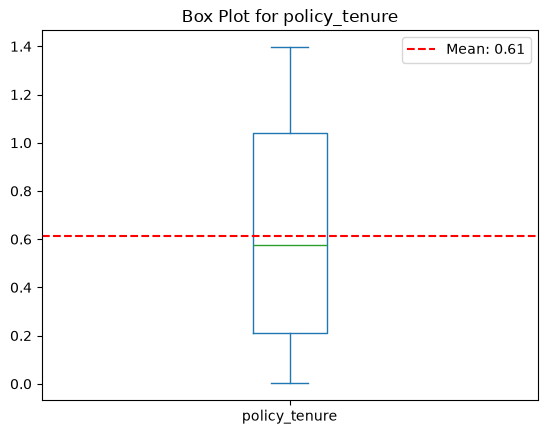

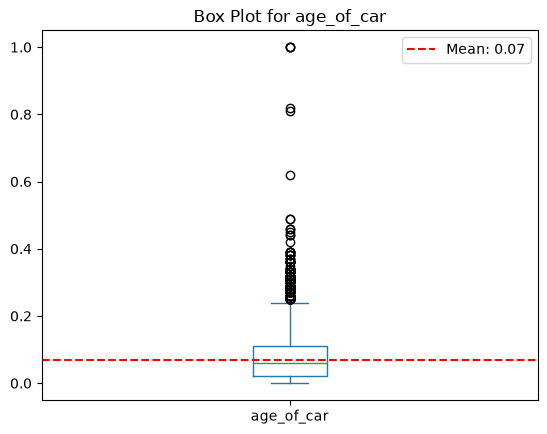

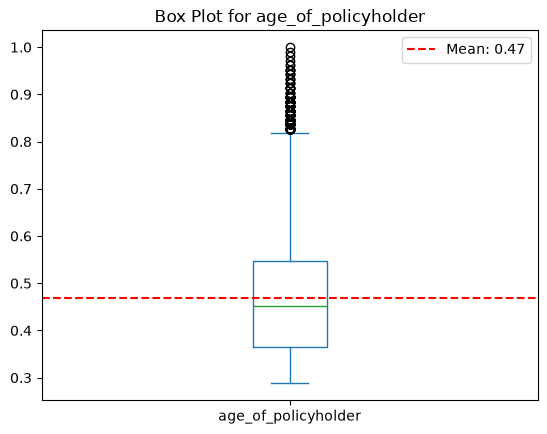

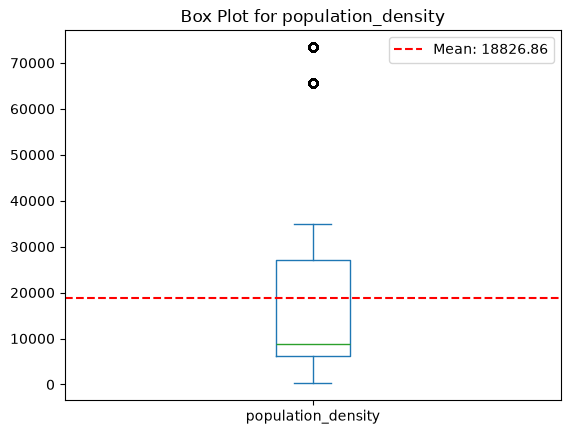

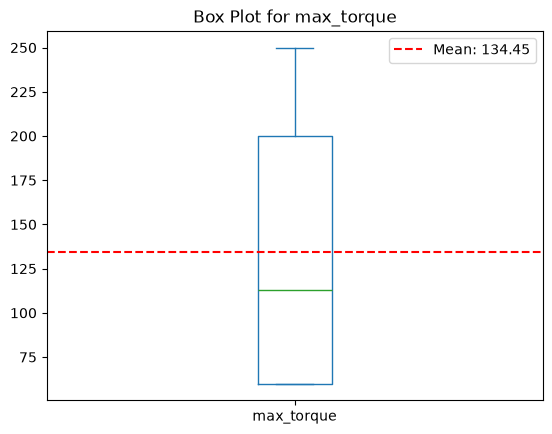

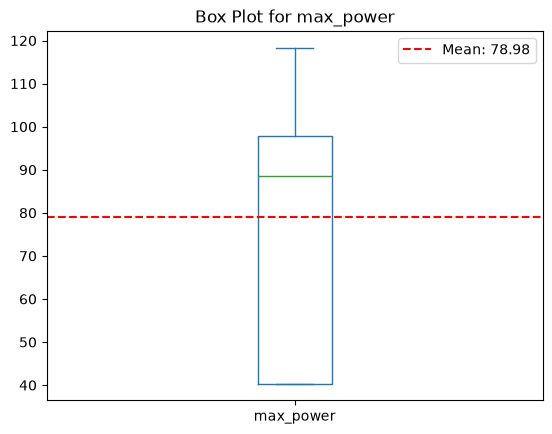

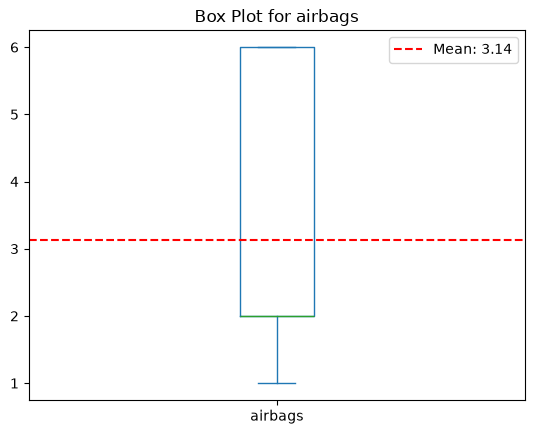

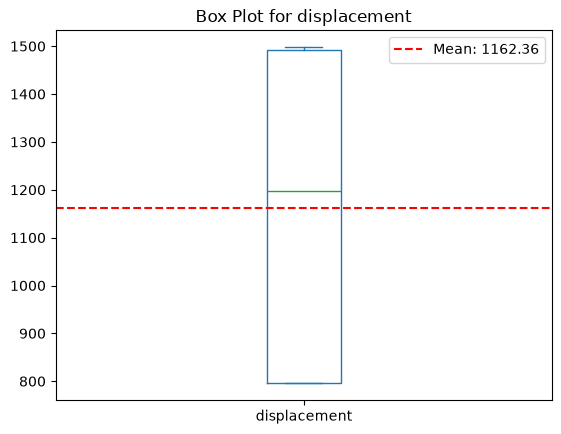

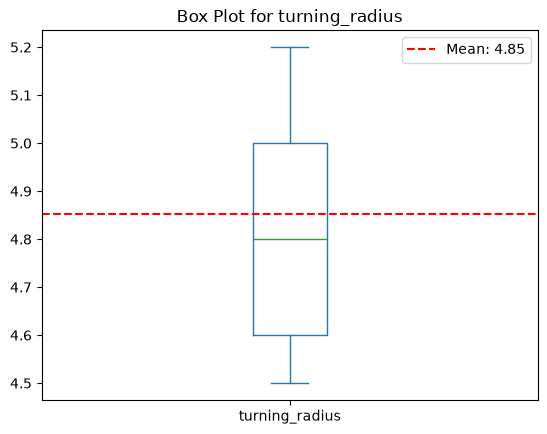

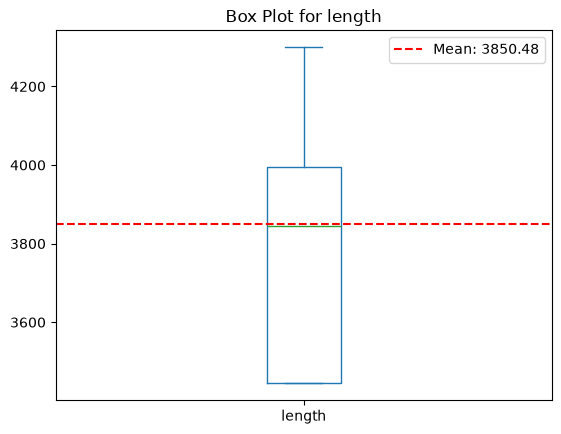

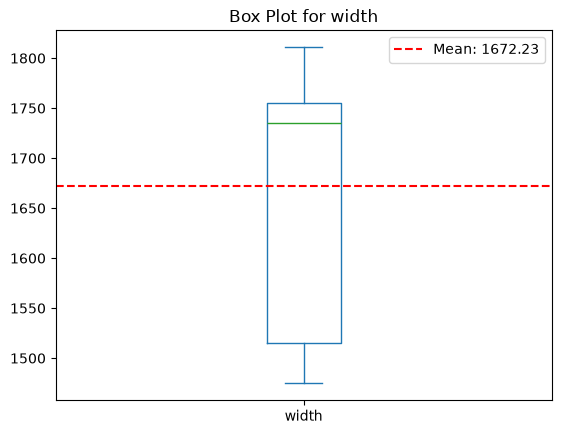

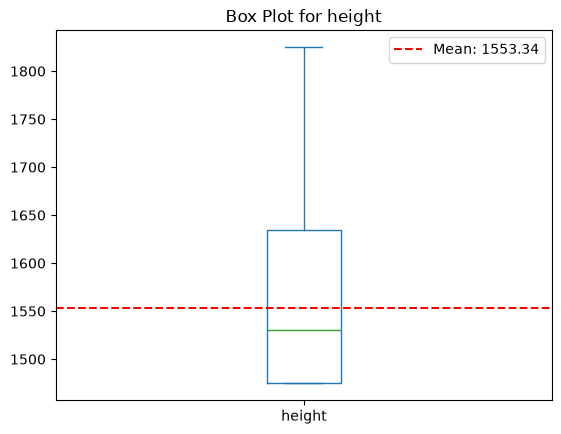

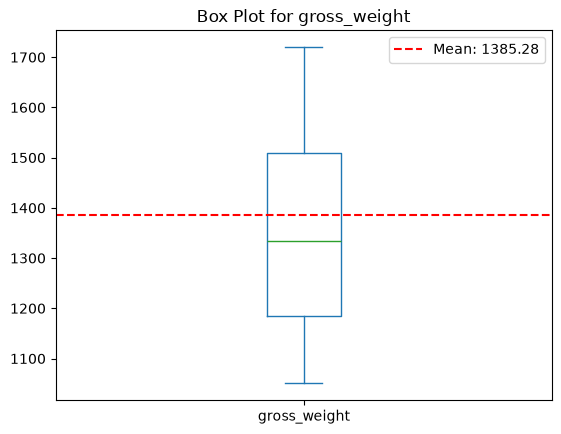

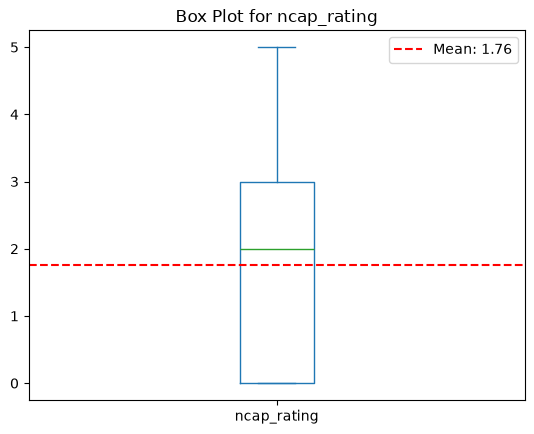

In [17]:
# Using box plot to find the outliers in numeric columns

for col in numeric_columns:
    insurance_df[col].plot(kind='box', title=f'Box Plot for {col}')
    plt.axhline(insurance_df[col].mean(), color='red', linestyle='--', label=f'Mean: {insurance_df[col].mean():.2f}')
    plt.legend()
    plt.show()



In [18]:
for i in numeric_columns:
    upper_bound= insurance_df[i].quantile(0.75) 
    lower_bound= insurance_df[i].quantile(0.25) 
    iqr = upper_bound - lower_bound
    insurance_df[i] = insurance_df[i].clip(
        lower=lower_bound - 1.5 * iqr,
        upper=upper_bound + 1.5 * iqr
    )
 




#### Outlier report

1. Most of numeric column doesn't have any outliers
2. There are outliers in column age_of_policyholder, age of the car and  population.


## Categorical columns encoding

In [19]:
# creating backup of the original dataframe before encoding categorical columns
encoded_df = insurance_df.copy()

In [20]:
categorical_columns.pop(0)

'policy_id'

In [21]:
# Using pandas get_dummies to encode categorical columns into numerical columns. We will drop the first column to avoid the dummy variable trap.
encoded_df = pd.get_dummies(encoded_df, columns=categorical_columns)

In [22]:
# Displaying the shape of the encoded DataFrame
print('Shape of encoded DataFrame:', encoded_df.shape)

Shape of encoded DataFrame: (58592, 102)


In [23]:
encoded_df.to_csv(r"G:\data_analytics_and_genAI\Capstone_project\cleaned_dataset\cleaned_dataset.csv", index=False)

Looking for distribution of numric columns

In [24]:
print('Skew of numeric columns:\n', insurance_df[numeric_columns].skew().sort_values(ascending=False))

print('Kurtosis of numeric columns:\n', insurance_df[numeric_columns].kurtosis().sort_values(ascending=False))

Skew of numeric columns:
 population_density     1.162328
height                 1.035498
airbags                0.905946
max_torque             0.671799
age_of_car             0.651123
age_of_policyholder    0.615271
gross_weight           0.546949
turning_radius         0.420983
length                 0.145801
ncap_rating            0.085147
policy_tenure          0.053588
displacement          -0.105317
max_power             -0.236599
width                 -0.488392
dtype: float64
Kurtosis of numeric columns:
 height                 0.726162
population_density     0.603120
age_of_policyholder   -0.264168
age_of_car            -0.369041
ncap_rating           -0.776224
gross_weight          -1.023830
airbags               -1.135791
max_torque            -1.164825
turning_radius        -1.176646
length                -1.209006
displacement          -1.342401
max_power             -1.385648
width                 -1.443509
policy_tenure         -1.498350
dtype: float64


## creating group of columns by category

In [25]:
numeric_columns,categorical_columns= column_grouping_function(insurance_df)


['is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'is_claim']


Extracting Max power and Max Torque from the columns

## Mathematical description of data set

Skewness

1. columns like height and population density are highly right skewed. 
2. Rest are close to normal distributions.

Kurtosis 

1. columns like height and population density has a standard normal right skewed distribution.
2. Others columns has less extreame values.



# EDA

## Univariate Analysis

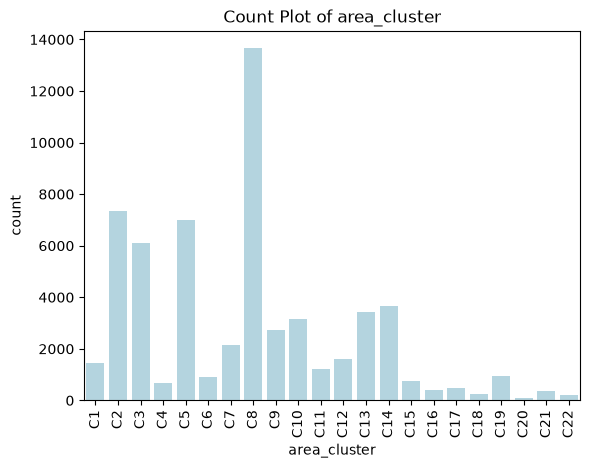

<Figure size 1000x1200 with 0 Axes>

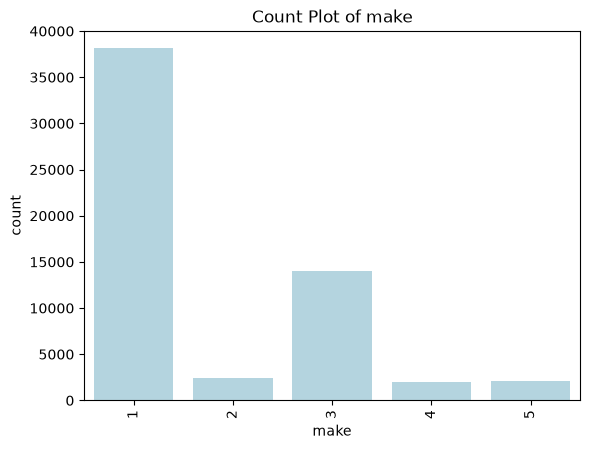

<Figure size 1000x1200 with 0 Axes>

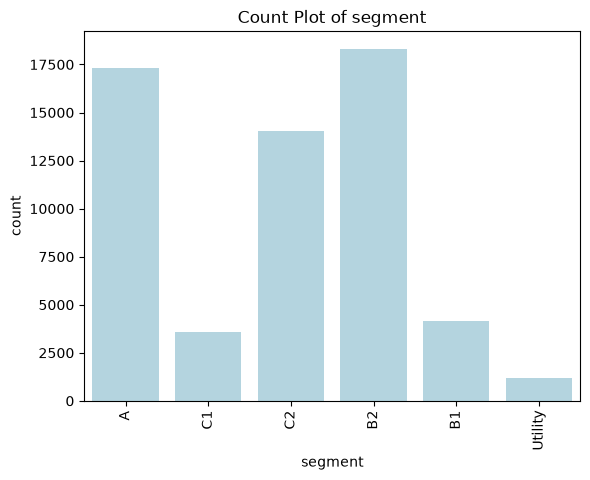

<Figure size 1000x1200 with 0 Axes>

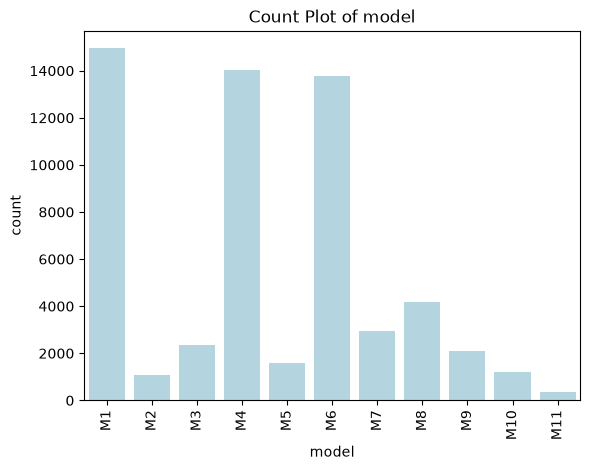

<Figure size 1000x1200 with 0 Axes>

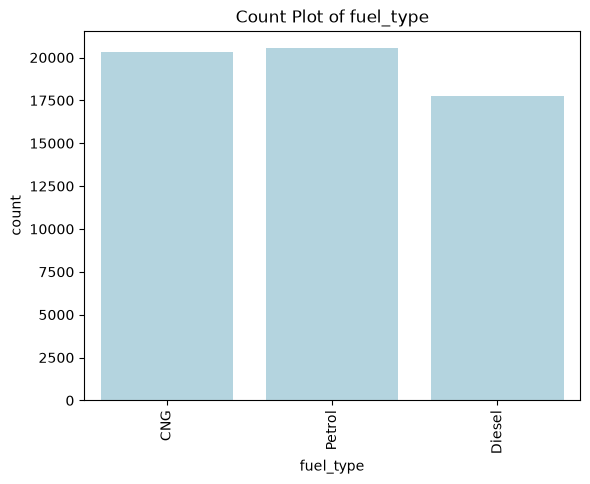

<Figure size 1000x1200 with 0 Axes>

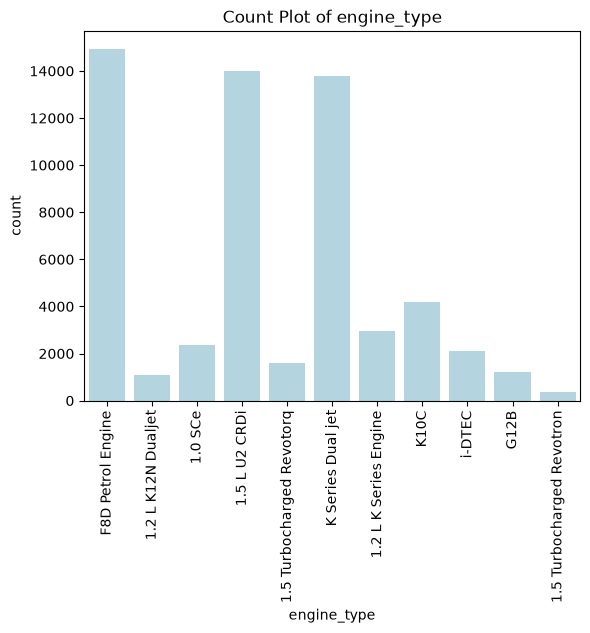

<Figure size 1000x1200 with 0 Axes>

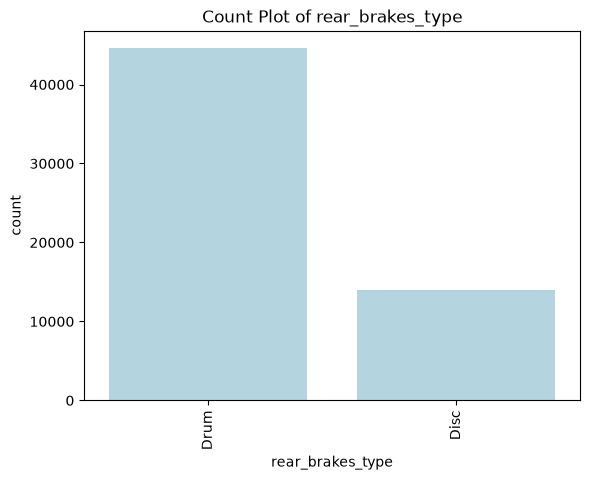

<Figure size 1000x1200 with 0 Axes>

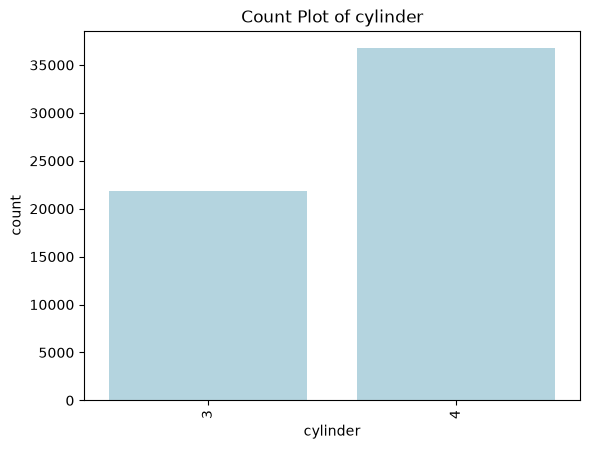

<Figure size 1000x1200 with 0 Axes>

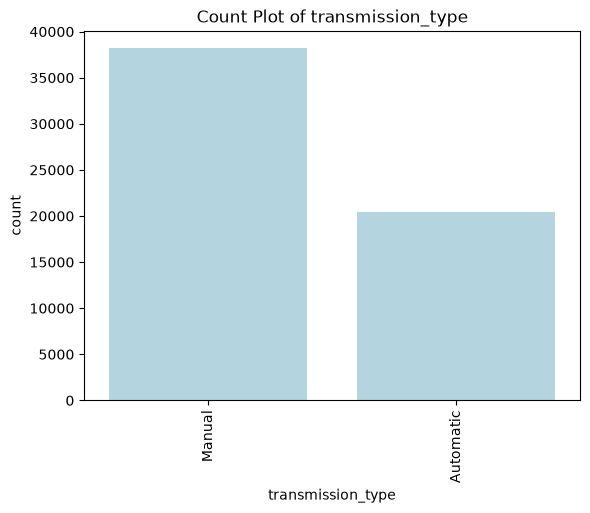

<Figure size 1000x1200 with 0 Axes>

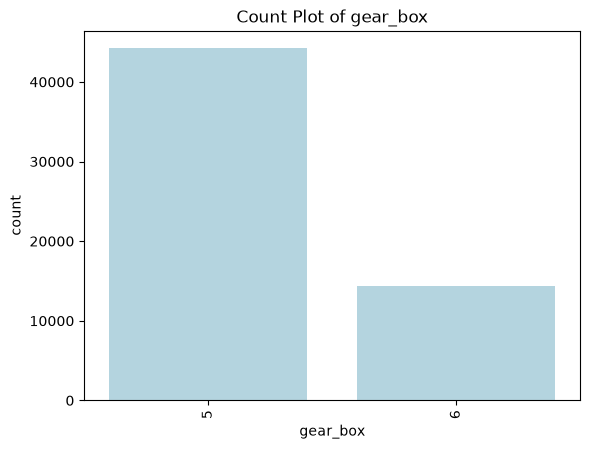

<Figure size 1000x1200 with 0 Axes>

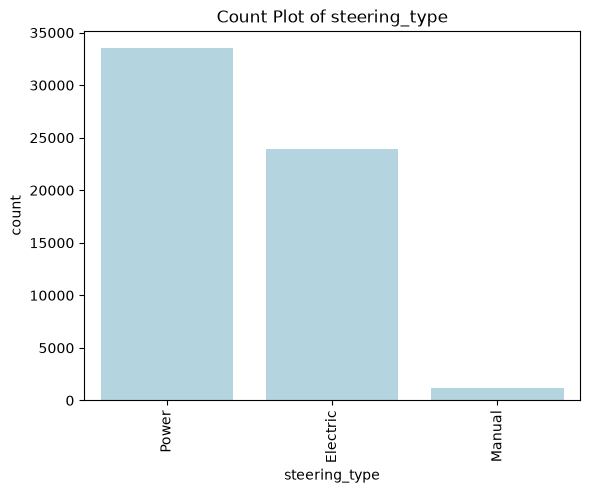

<Figure size 1000x1200 with 0 Axes>

In [26]:
for col in categorical_columns:

    sns.countplot(data=insurance_df, x=col, color='lightblue')
    plt.xticks(rotation=90)
    plt.title(f"Count Plot of {col}")
    plt.figure(figsize=(10, 12))
    plt.show()

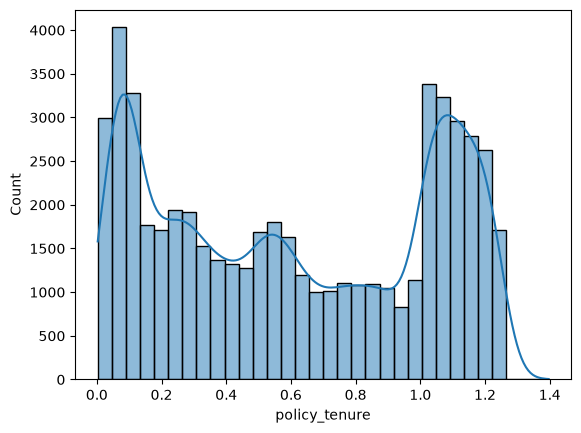

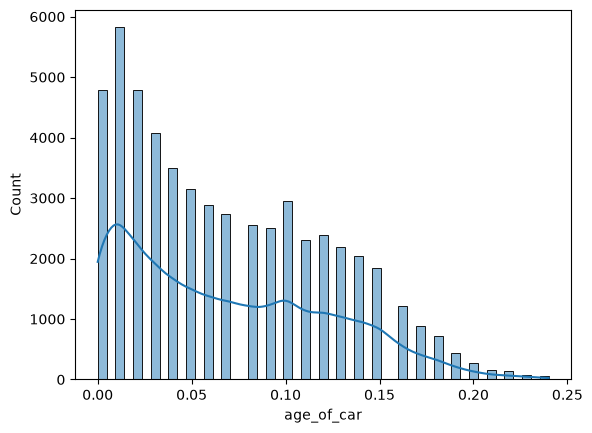

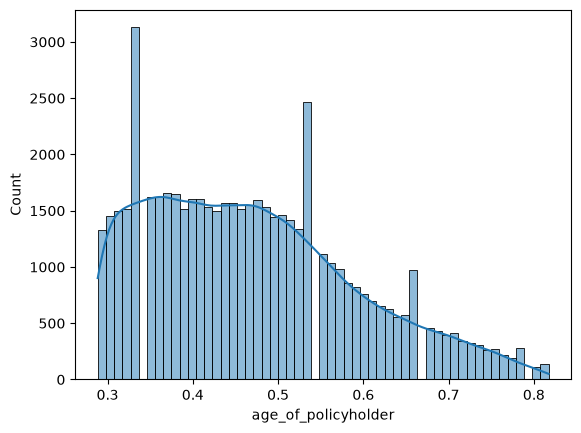

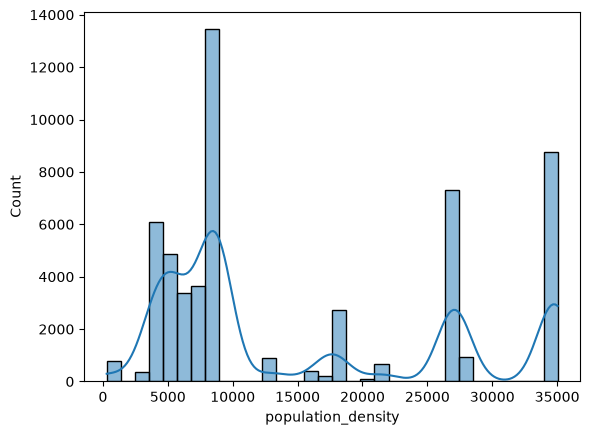

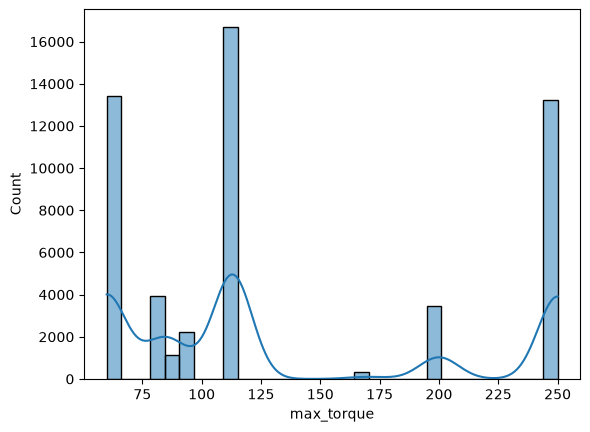

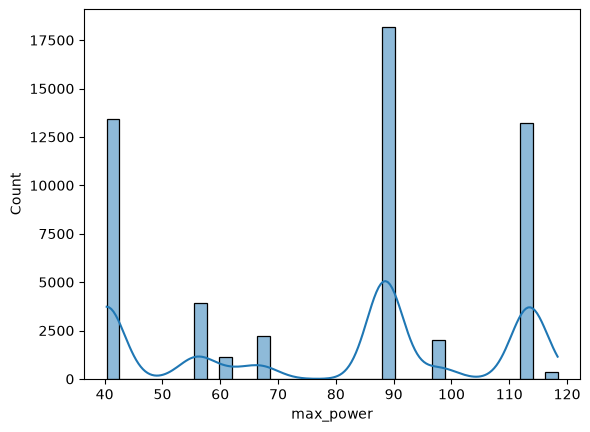

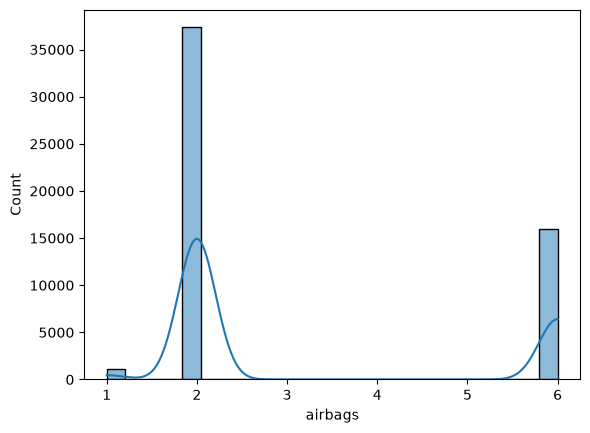

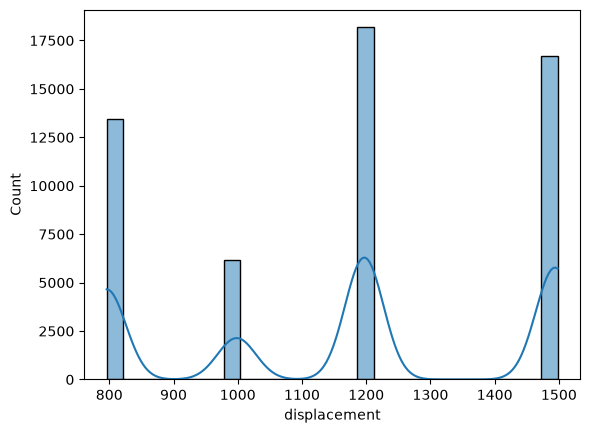

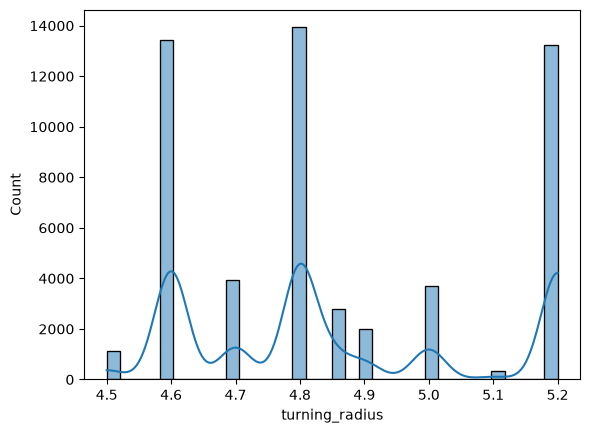

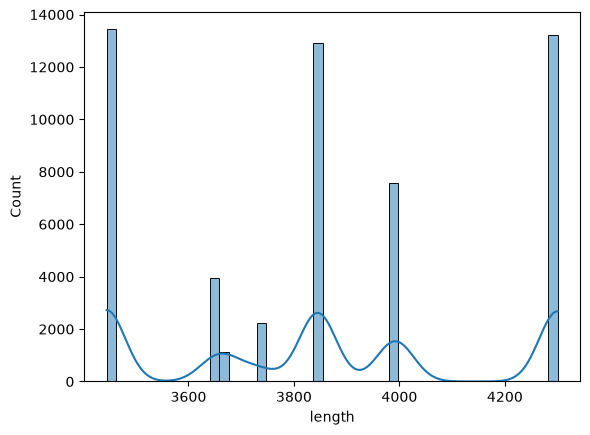

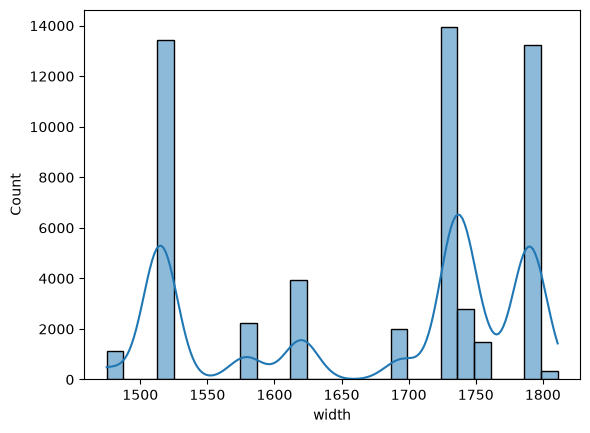

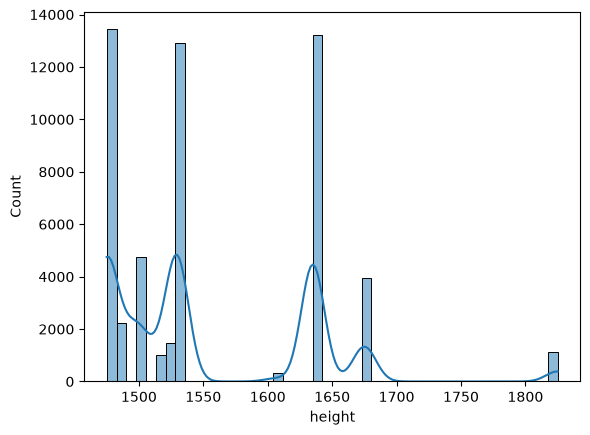

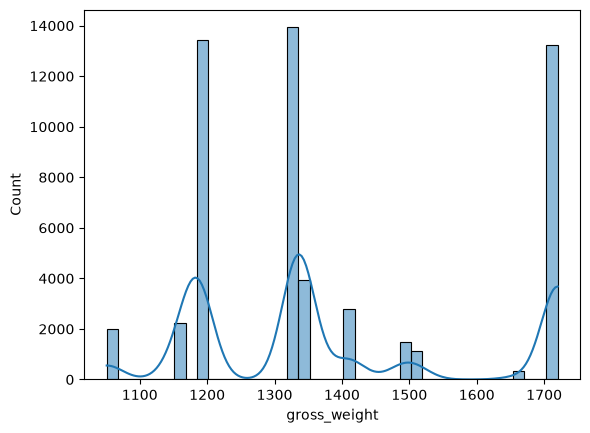

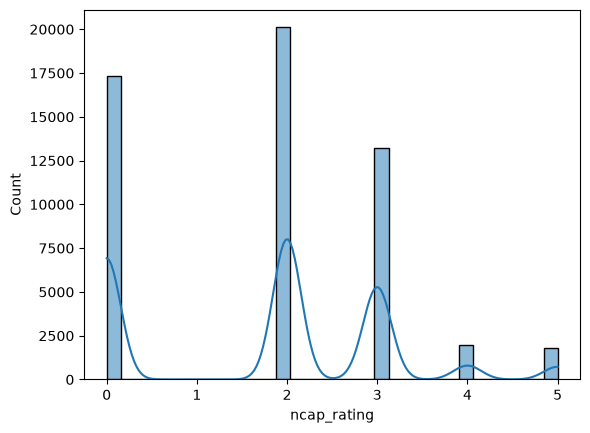

In [27]:
# Creating histogram for numeric columns Where density distribution is visible
for col in numeric_columns:
    sns.histplot(data=insurance_df, x=col, kde= True)
    plt.show()

## Bivariate Analysis


In [28]:
for col in ['age_of_policyholder', 'age_of_car', 'population_density']:
    insurance_df[col + '_bin'] = pd.qcut(insurance_df[col], q=5, labels=[f'Q{i+1}' for i in range(5)])

C:\Users\User\AppData\Local\Temp\ipykernel_37628\733000972.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  insurance_df.groupby(col)['is_claim'].mean().plot(kind='bar', title=f'Claim Rate by {col}')


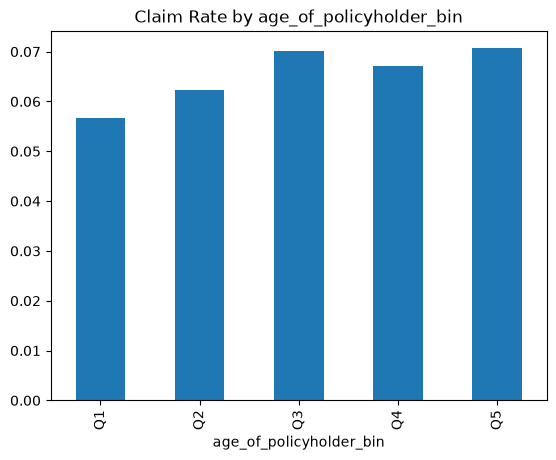

C:\Users\User\AppData\Local\Temp\ipykernel_37628\733000972.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  insurance_df.groupby(col)['is_claim'].mean().plot(kind='bar', title=f'Claim Rate by {col}')


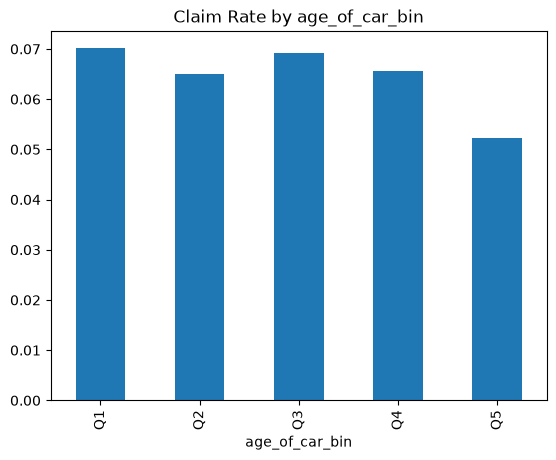

C:\Users\User\AppData\Local\Temp\ipykernel_37628\733000972.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  insurance_df.groupby(col)['is_claim'].mean().plot(kind='bar', title=f'Claim Rate by {col}')


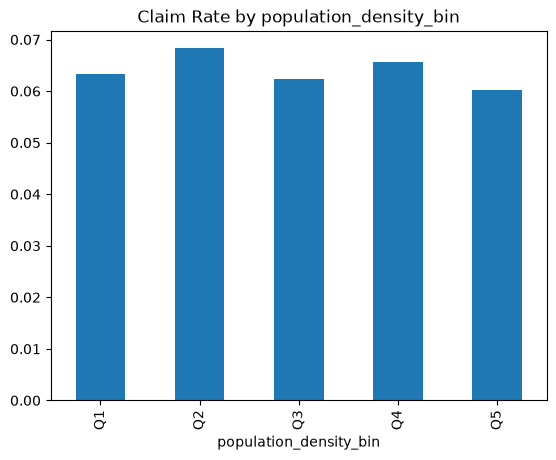

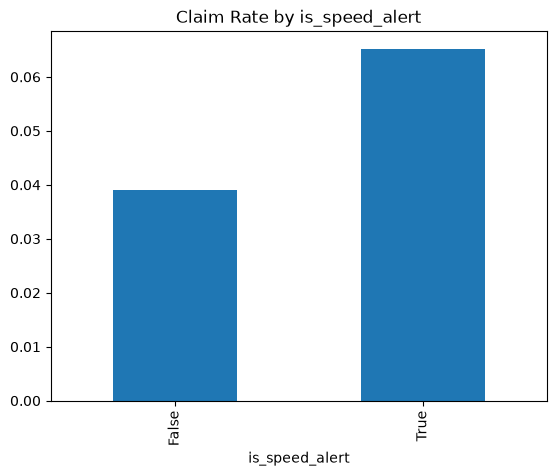

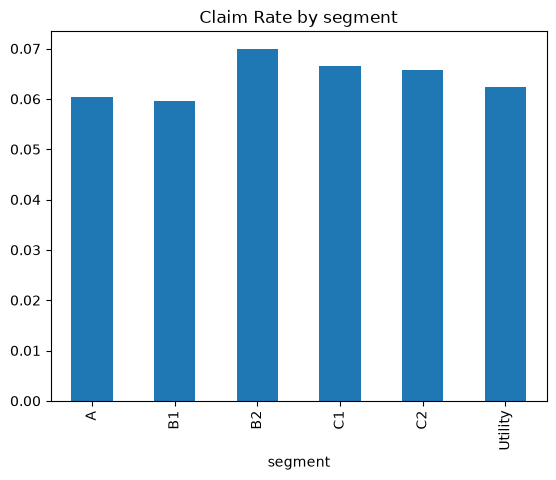

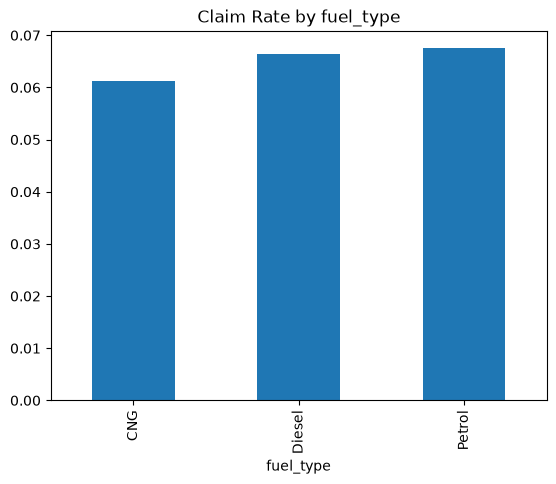

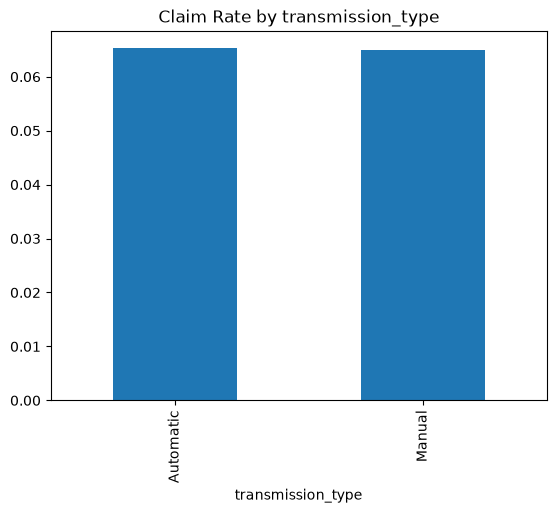

In [29]:
for col in ['age_of_policyholder_bin', 'age_of_car_bin', 'population_density_bin', 'is_speed_alert', 'segment', 'fuel_type', 'transmission_type']:
    insurance_df.groupby(col)['is_claim'].mean().plot(kind='bar', title=f'Claim Rate by {col}')
    plt.show()

## Multivariate Analysis

In [32]:
selected_cols = numeric_columns + (['is_claim'] if 'is_claim' not in numeric_columns else [])

corr_with_claim = insurance_df[selected_cols].corr()['is_claim'].sort_values(ascending=False)

corr_with_claim_df = pd.DataFrame(corr_with_claim).reset_index()

corr_with_claim_df["rank"] = corr_with_claim_df['is_claim'].rank(ascending=False)

display(corr_with_claim_df)

,index,is_claim,rank
0,is_claim,1.000000,1.0
1,policy_tenure,0.078747,2.0
2,age_of_policyholder,0.022318,3.0
3,width,0.009947,4.0
4,max_power,0.007698,5.0
5,displacement,0.007678,6.0
6,length,0.006495,7.0
7,max_torque,0.004294,8.0
8,gross_weight,0.003894,9.0
9,ncap_rating,0.003800,10.0


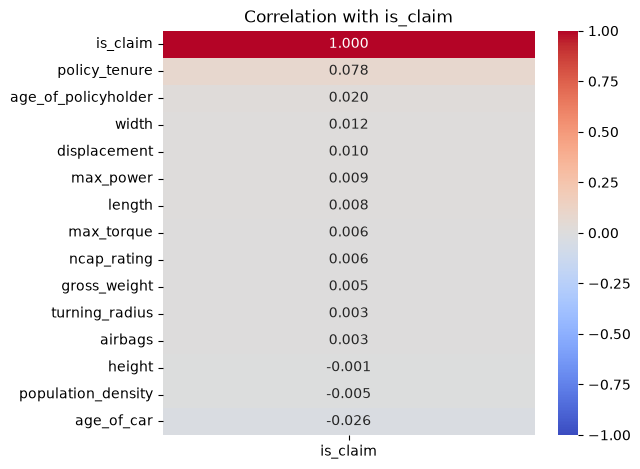

In [ ]:
# heatmap of correlation with is_claim

plt.figure(figsize=(6, len(corr_with_claim)*0.35))
sns.heatmap(corr_with_claim.to_frame(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".3f", cbar=True)
plt.title('Correlation with is_claim')
plt.yticks(rotation=0)
plt.show()

<Axes: >

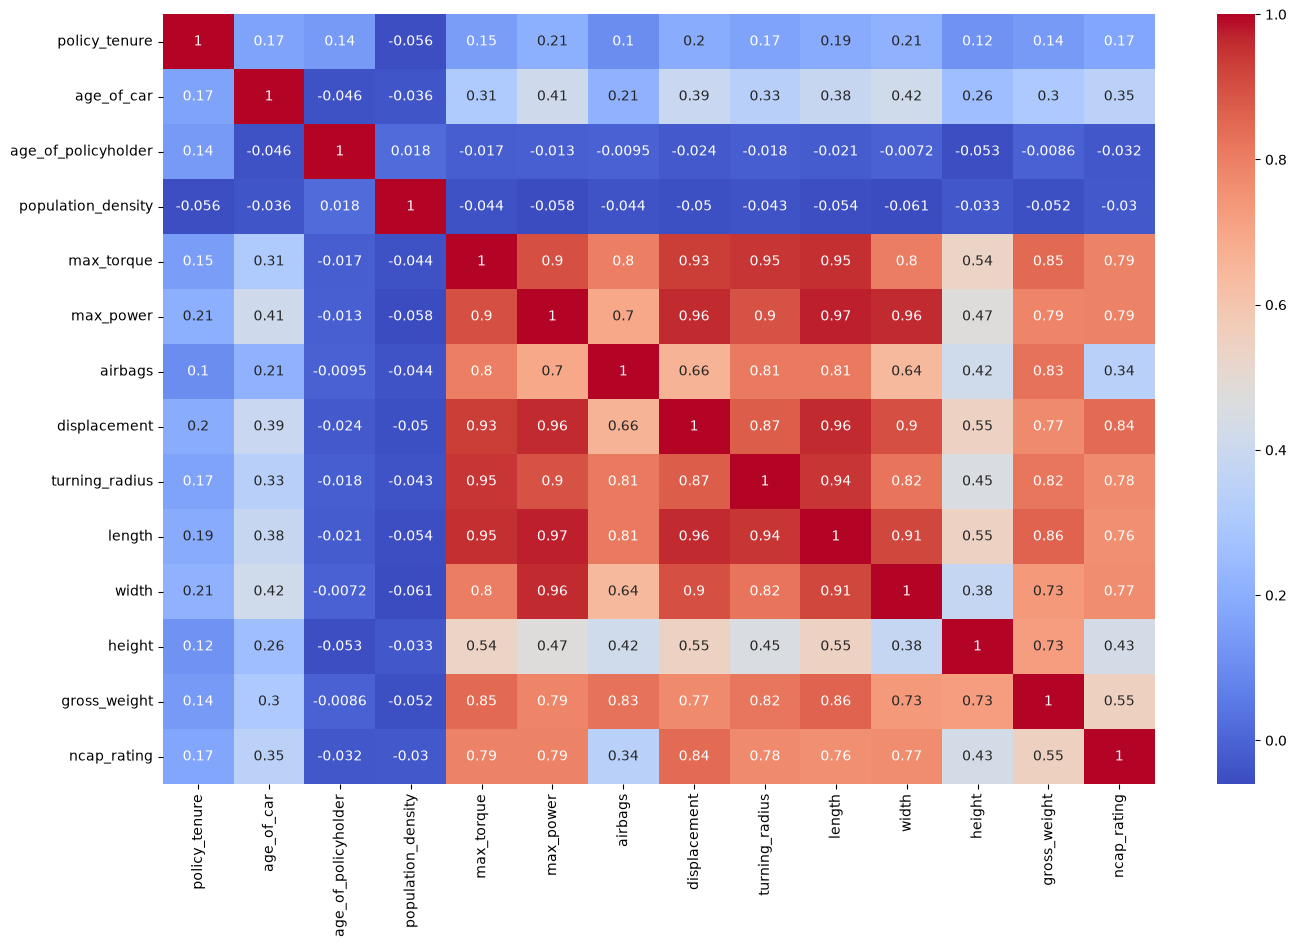

In [31]:
plt.figure(figsize=(16,10))

sns.heatmap(data= insurance_df[numeric_columns].corr(), cmap='coolwarm', annot= True)


# Feature Engineering

In [32]:
# Importing necessary libraries required for feature engineering
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression


### Creting new feature

1. High risk driver flag

In [33]:
# Creating a new column 'High_risk_driver_flag' in the encoded_df DataFrame. This column will be True for policyholders who are in the lowest 25% of age and have an NCAP rating less than 2, indicating they are high-risk drivers.
encoded_df['High_risk_driver_flag'] = (
    (encoded_df['age_of_policyholder'] < encoded_df['age_of_policyholder'].quantile(0.25))
    & (encoded_df['ncap_rating'].astype(int) <2 ))



In [34]:
# Checking the value count.
insurance_df['is_claim'].value_counts(normalize= True)

is_claim
False    0.93493
True     0.06507
Name: proportion, dtype: float64

In [35]:
# Checking the value count where 'High_risk_driver_flag' is true
encoded_df.loc[encoded_df['High_risk_driver_flag']]["is_claim"].value_counts(normalize= True)

is_claim
False    0.935627
True     0.064373
Name: proportion, dtype: float64

In [36]:
# Creating new feature safety score Which is the sum of all the safety features in the data set

encoded_df['safety_score'] = (
    insurance_df['airbags'].astype(float)
    + insurance_df['ncap_rating'].astype(float)
    + insurance_df['is_speed_alert'].astype(float)
    + insurance_df['is_ecw'].astype(float)
    + insurance_df['is_day_night_rear_view_mirror'].astype(float)
    + insurance_df['is_driver_seat_height_adjustable'].astype(float)
    + insurance_df['is_power_steering'].astype(float)
    + insurance_df['is_central_locking'].astype(float)
    + insurance_df['is_power_door_locks'].astype(float)
    + insurance_df['is_brake_assist'].astype(float)
    + insurance_df['is_rear_window_defogger'].astype(float)
    + insurance_df['is_rear_window_washer'].astype(float)
    + insurance_df['is_rear_window_wiper'].astype(float)
    + insurance_df['is_front_fog_lights'].astype(float)
    + insurance_df['is_parking_camera'].astype(float)
    + insurance_df['is_parking_sensors'].astype(float)
    + insurance_df['is_tpms'].astype(float)
    + insurance_df['is_adjustable_steering'].astype(float)
    + insurance_df['is_esc'].astype(float)
    + np.where(insurance_df['rear_brakes_type'] == 'Disc', 1.0, 0.0)
)


In [37]:
# Looking for unique value in safety score
encoded_df['safety_score'].unique()

array([ 5., 18., 11., 26., 14., 15., 22., 10.,  3., 17.])

In [38]:
# Verifying The changes
encoded_df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,max_torque,max_power,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,displacement,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,area_cluster_C11,area_cluster_C12,area_cluster_C13,area_cluster_C14,area_cluster_C15,area_cluster_C16,area_cluster_C18,area_cluster_C19,area_cluster_C2,area_cluster_C20,area_cluster_C21,area_cluster_C22,area_cluster_C3,area_cluster_C4,area_cluster_C5,area_cluster_C6,area_cluster_C7,area_cluster_C8,area_cluster_C9,make_2,make_3,make_4,make_5,segment_B1,segment_B2,segment_C1,segment_C2,segment_Utility,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9,fuel_type_Diesel,fuel_type_Petrol,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 L U2 CRDi,engine_type_1.5 Turbocharged Revotorq,engine_type_1.5 Turbocharged Revotron,engine_type_F8D Petrol Engine,engine_type_G12B,engine_type_K Series Dual jet,engine_type_K10C,engine_type_i-DTEC,rear_brakes_type_Drum,cylinder_4,transmission_type_Manual,gear_box_6,steering_type_Manual,steering_type_Power,High_risk_driver_flag,safety_score
0,ID00001,0.515874,0.05,0.644231,4990,60.0,40.36,2,False,False,False,True,False,796,4.6,3445,1515,1475,1185,False,False,False,False,False,False,False,True,False,False,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,5.0
1,ID00002,0.672619,0.02,0.375000,27003,60.0,40.36,2,False,False,False,True,False,796,4.6,3445,1515,1475,1185,False,False,False,False,False,False,False,True,False,False,False,True,0,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,5.0
2,ID00003,0.841110,0.02,0.384615,4076,60.0,40.36,2,False,False,False,True,False,796,4.6,3445,1515,1475,1185,False,False,False,False,False,False,False,True,False,False,False,True,0,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,5.0
3,ID00004,0.900277,0.11,0.432692,21622,113.0,88.50,2,True,True,False,True,True,1197,4.8,3995,1735,1515,1335,True,False,False,True,True,True,True,True,True,True,True,True,2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,18.0
4,ID00005,0.596403,0.11,0.634615,34738,91.0,67.06,2,False,False,False,False,True,999,5.0,3731,1579,1490,1155,False,False,False,False,False,True,True,True,False,True,True,True,2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,Fa

In [39]:
# Creating feature power to weight ratio which is a division of Max power by gross weight 
encoded_df['Power_to_weight_ratio'] = encoded_df['max_power']/ encoded_df['gross_weight']

## Corelation 

<Figure size 160000x160000 with 0 Axes>

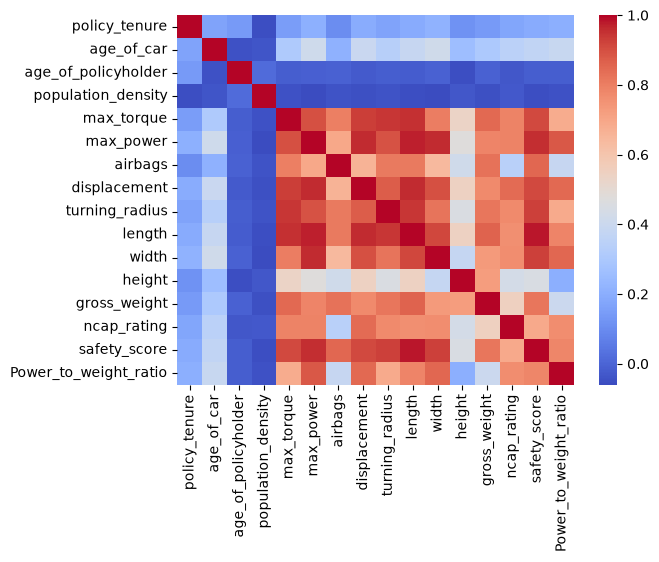

In [40]:
# Looking for correlation heatmap
sns.heatmap(data=encoded_df.select_dtypes(include= 'number').corr(),cmap= 'coolwarm')
plt.Figure(figsize=(1600,1600))

In [41]:
# find numeric feature pairs with absolute correlation > 0.9
num = encoded_df.select_dtypes(include='number')
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = upper.stack().reset_index()
high_corr.columns = ['feature_1', 'feature_2', 'corr']
high_corr = high_corr[high_corr['corr'] > 0.9].sort_values('corr', ascending=False)

if high_corr.empty:
    print("No pairs with abs(correlation) > 0.9 found.")
else:
    print("Pairs with abs(correlation) > 0.9:")
    print(high_corr.to_string(index=False))

Pairs with abs(correlation) > 0.9:
     feature_1      feature_2     corr
        length   safety_score 0.980190
     max_power         length 0.972602
     max_power   displacement 0.962087
  displacement         length 0.961020
     max_power          width 0.958694
     max_power   safety_score 0.955044
    max_torque         length 0.951917
    max_torque turning_radius 0.945993
turning_radius         length 0.944310
    max_torque   displacement 0.930952
         width   safety_score 0.927095
turning_radius   safety_score 0.926834
        length          width 0.914355
    max_torque   safety_score 0.911665
  displacement   safety_score 0.909806


### droping highly correlated features based on correlation matrix  manually


In [42]:
# droping highly correlated features based on correlation matrix

encoded_df = encoded_df.drop(columns= ['displacement'])
encoded_df = encoded_df.drop(columns=['max_torque'])
encoded_df = encoded_df.drop(columns= ['turning_radius'])
encoded_df = encoded_df.drop(columns= ['max_power'])
encoded_df = encoded_df.drop(columns= ['length'])
encoded_df = encoded_df.drop(columns=['width'])

In [43]:
encoded_df.dtypes

policy_id                 object
policy_tenure            float64
age_of_car               float64
age_of_policyholder      float64
population_density         int64
                          ...   
steering_type_Manual        bool
steering_type_Power         bool
High_risk_driver_flag       bool
safety_score             float64
Power_to_weight_ratio    float64
Length: 86, dtype: object

## VIF

In [44]:
# Use VIF to identify multicollinear features and select features with acceptable VIF
X = encoded_df.drop(columns=['is_claim'])
X = X.select_dtypes(include=[np.number])  # Ensure only numeric columns are included for VIF calculation
# Calculate VIF for each feature in the dataset
def calculate_vif(X):
    vif_data = pd.DataFrame()
    vif_data['feature'] = X.columns
    vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_data.sort_values('VIF', ascending=False).reset_index(drop=True)


vif_df = calculate_vif(X)
display(vif_df)



,feature,VIF
0,height,612.391179
1,gross_weight,557.317262
2,safety_score,283.866896
3,Power_to_weight_ratio,188.912149
4,airbags,78.176419
5,age_of_policyholder,16.004057
6,ncap_rating,10.352963
7,policy_tenure,3.508126
8,age_of_car,3.276115
9,population_density,2.817879


Dropping high VIF features manually one by one

In [45]:
X = X.drop(columns=['gross_weight'])
X = X.drop(columns=['height'])
X = X.drop(columns=['Power_to_weight_ratio'])
X = X.drop(columns=['ncap_rating'])
X = X.drop(columns=['airbags'])

In [46]:
# Rechecking VIF 
vif_df = calculate_vif(X)
display(vif_df)

,feature,VIF
0,age_of_policyholder,6.099476
1,safety_score,4.878469
2,policy_tenure,3.418749
3,age_of_car,3.017306
4,population_density,2.570635


In [48]:
# Dropping High VIF Pictures from the encoded_df
encoded_df = encoded_df.drop(columns=['gross_weight', 'height', 'Power_to_weight_ratio', 'ncap_rating', 'airbags'])

In [49]:
# Exporting encoded_df to csv
encoded_df.to_csv(r"G:\data_analytics_and_genAI\Capstone_project\cleaned_dataset\cleaned_dataset_1.csv", index=False)